# Explore: corridor origins, catchments and trends over time

The companion to `06_explore_corridor_profiles.ipynb`. That notebook compares corridors on a snapshot; this one
looks at **time** (the COVID shock and recovery, who gained and lost share, seasonality) and **geography** (whose
neighbourhoods feed each corridor, and which corridors share visitors).

Because the data come from two usable providers (S1 2019-2022 and S3 mid-2023-2025) with no overlap, every question about
change over time is asked in one of the two ways that survive that (`04_cross_segment_comparability`):

- **inside one segment**, using that segment's own index or shares; or
- **across the break only through relative measures** (share of the 21-corridor total with its uncertainty band, rank
  position), never raw levels.

Sections:

1. **What can be compared over time?** The comparability rules, in one table.
2. **COVID shock and recovery**, strictly within the 2019-2022 segment (S1).
3. **Who gained and lost share?** Share of the 21-corridor total by year, with the break marked.
4. **Seasonality** within single years.
5. **Origin over time**, inside each segment.
6. **Catchment maps** for all 21 corridors.
7. **Catchment overlap**: which corridors compete for the same neighbourhoods?
8. **Who lives where visitors come from?** Demographics of origin block groups.
9. **Which districts over-index at which corridors?**

---

| | |
|---|---|
| **Inputs** | `src/data/activity/corridor_metrics.json`, `legend_breaks.json`; `data/activity/processed/*`; `src/data/OAK_BG.geo.json` |
| **Outputs** | Figures and tables in this notebook only |
| **Run after** | `01_` ... `05_` |

In [1]:
import json
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import leaves_list, linkage
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", message="Unable to import Axes3D")

/home/aniket/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
# --- Paths ---
# Repo root = nearest parent folder containing package.json, so this notebook runs from any depth.
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "package.json").exists())
DATA = ROOT / "data"                 # raw + intermediate files
SRC_DATA = ROOT / "src" / "data"     # final outputs consumed directly by the web app
PROCESSED_DIR = DATA / "activity" / "processed"

METRICS_JSON = PROCESSED_DIR / "corridor_metrics_all.json"   # full copy written by 05_
LEGEND_BREAKS_JSON = SRC_DATA / "activity" / "legend_breaks.json"
STOPS_CSV = PROCESSED_DIR / "corridor_stops.csv.gz"
ORIGIN_CATEGORY_CSV = PROCESSED_DIR / "corridor_origin_categories_monthly.csv.gz"
BG_ORIGIN_CSV = PROCESSED_DIR / "corridor_bg_origin.csv.gz"
DISTRICT_ORIGIN_CSV = PROCESSED_DIR / "corridor_district_origin.csv"
BG_DISTRICT_CSV = PROCESSED_DIR / "bg_district_weights.csv"
BAY_DENOMS_CSV = PROCESSED_DIR / "bay_month_denoms.csv.gz"
CORRIDOR_LOOKUP_CSV = PROCESSED_DIR / "corridor_lookup.csv"
OAK_BG_GEOJSON = SRC_DATA / "OAK_BG.geo.json"
MAP_CORRIDORS_GEOJSON = SRC_DATA / "OAK_CORRIDORS.geo.json"
SET2_CORRIDORS_GPKG = DATA / "corridors" / "corridors2" / "corridors2_final_original.gpkg"

# --- Parameters ---
TIME_PERIODS = ["all", "evening", "nine-five", "weekdays", "weekends"]
PERIOD_LABELS = {"all": "All", "evening": "Evenings", "nine-five": "Weekday daytime", "weekdays": "Weekdays", "weekends": "Weekends"}
WORK_CRS = "EPSG:3310"
S1_FIRST, S1_LAST = "201901", "202212"           # provider segment 1
S3_FIRST = "202307"
BOUNDARY_WINDOW = 3                              # months either side of a segment break used for the break test
COVID_MONTH = "202004"                           # first full month after the March 2020 shelter-in-place order
BASELINE_YEAR, RECOVERY_YEAR = "2019", "2022"
SEASON_YEARS = ["2019", "2024", "2025"]          # full calendar years each wholly inside one segment
DEMOGRAPHIC_VARS = {
    "median_household_income": "Median household income ($)",
    "per_capita_income": "Per-capita income ($)",
    "renter_share": "Renter share of households",
    "median_age": "Median age",
}
N_MAP_COLS = 5

# --- Chart styling (see dataviz skill: fixed categorical order, single-hue sequential) ---
CATEGORICAL_PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQUENTIAL_BLUE_RAMP = ["#cde2fb", "#9ec3f2", "#6da7ec", "#2a78d6", "#1f62b4", "#184f95", "#0f3563"]
GREEN_RAMP = ["#EAF3EC", "#B9D9C1", "#87BE96", "#57A36C", "#2C683D"]   # same ramp as LayerConfig.js activity layers
PERIOD_COLORS = dict(zip(TIME_PERIODS, CATEGORICAL_PALETTE))
SEG_COLOR = {"S1": CATEGORICAL_PALETTE[0], "S3": CATEGORICAL_PALETTE[2]}
CHART_GRID_COLOR = "#e1e0d9"
CHART_MUTED_TEXT = "#898781"
MAP_BASE = "#eceae3"

In [3]:
def style_axis(ax, grid_axis="y"):
    """Shared cosmetic cleanup: recessive grid, no top/right spines."""
    ax.grid(axis=grid_axis, color=CHART_GRID_COLOR, linewidth=0.6, zorder=0)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    ax.tick_params(colors=CHART_MUTED_TEXT)


def to_dt(year_month):
    return pd.to_datetime(pd.Series(year_month).astype(str), format="%Y%m")


def shade_segments(ax, segments, months_dt):
    for i, seg in enumerate(segments):
        lo, hi = pd.to_datetime(seg["start"], format="%Y%m"), pd.to_datetime(seg["end"], format="%Y%m") + pd.offsets.MonthEnd(0)
        if i % 2 == 0:
            ax.axvspan(lo, hi, color=CHART_GRID_COLOR, alpha=0.45, zorder=0)
        ax.text(lo + (hi - lo) / 2, ax.get_ylim()[1], seg["id"], ha="center", va="top", color=CHART_MUTED_TEXT, fontsize=8)

## Load data

In [4]:
with open(METRICS_JSON) as f:
    M = json.load(f)
meta, C = M["meta"], M["corridors"]
names = {slug: c["name"] for slug, c in C.items()}
slugs = list(C)
months = meta["months"]
segments = meta["segments"]
months_dt = to_dt(months)

stops = pd.read_csv(STOPS_CSV)
stops["year_month"] = stops.year_month.astype(str)
origin_cat = pd.read_csv(ORIGIN_CATEGORY_CSV)
bg_origin = pd.read_csv(BG_ORIGIN_CSV, dtype={"bg_geoid": str})
bay = pd.read_csv(BAY_DENOMS_CSV)
bay["year_month"] = bay.year_month.astype(str)
legend_breaks = json.load(open(LEGEND_BREAKS_JSON))

# adjusted monthly devices as a (month x corridor) frame per period, from the JSON the front end reads
monthly = {p: pd.DataFrame({s: C[s]["monthly"][p]["devices"] for s in slugs}, index=months).astype(float) for p in TIME_PERIODS}
print(f"{len(slugs)} corridors x {len(months)} months; segments: {[s['id'] for s in segments]}")

21 corridors x 84 months; segments: ['S1', 'S2', 'S3']


## 1. What can be compared over time?

| Segment | Months | Reference Bay home panel | Used? |
|---|---|---|---|
| S1 | Jan 2019 - Dec 2022 | ~211,000 devices | yes |
| S2 | Jan - Jun 2023 | ~17,000 devices | **no**: too thin (a few hundred devices per corridor-month) |
| S3 | Jul 2023 - Dec 2025 | ~2,290,000 devices | yes |

`04_cross_segment_comparability` tested what survives the provider change. In short: the provider effect is **not** a common
multiplier (corridors differ by a factor of ~1.4 in either direction beyond ordinary change), so absolute levels are never joined;
but a corridor's **share of the 21-corridor total**, its **Oakland share** and its **share of near/far visitors** keep their
corridor ranking across the break, while weekend share, evening share, repeat % and own-district share do not.

,rank correlation inside S1,ACROSS the break,inside S3,may be compared across the break?
metric,,,,
Share of the 21-corridor total (activity level),0.99,0.93,0.96,yes: as rank position
Oakland share of visitors,0.97,0.94,0.96,yes: as rank position
Share of visitors within 5 km,0.98,0.93,0.92,yes: as rank position
Share of visitors beyond 25 km,0.98,0.94,0.79,yes: as rank position
Weekend share of visits,0.95,0.84,0.60,no: within a segment only
Evening share of visits,0.93,0.69,0.92,no: within a segment only
Repeat-visitor %,0.99,0.31,0.85,no: within a segment only
Share from own council district,0.98,0.76,0.93,no: within a segment only


Share of the 21-corridor total across the break carries a band of x/1.416 to x*1.416.


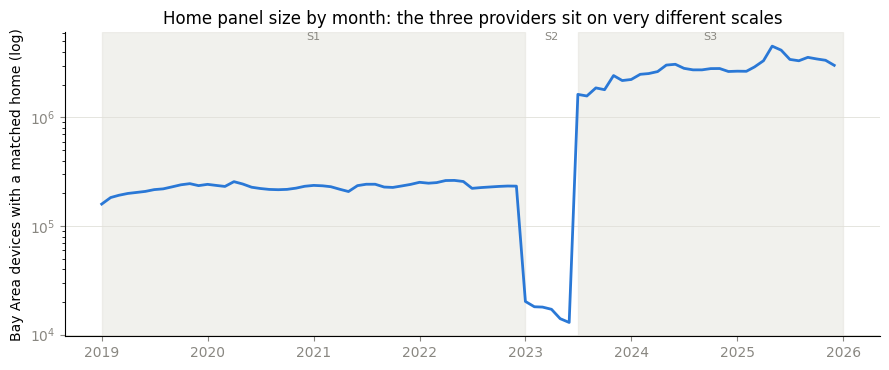

In [5]:
rules = meta["comparability"]["rules"]
rule_labels = {
    "devices_share": "Share of the 21-corridor total (activity level)",
    "oakland_pct": "Oakland share of visitors",
    "within_5km_pct": "Share of visitors within 5 km",
    "beyond_25km_pct": "Share of visitors beyond 25 km",
    "weekend_pct": "Weekend share of visits",
    "evening_pct": "Evening share of visits",
    "repeat_pct": "Repeat-visitor %",
    "in_district_pct": "Share from own council district",
}
rank_info = json.load(open(PROCESSED_DIR / "comparability.json"))["rank_stability"]
rule_table = pd.DataFrame({
    "metric": [rule_labels[k] for k in rules],
    "rank correlation inside S1": [rank_info[m]["s1_within"] for m in rank_info],
    "ACROSS the break": [rank_info[m]["break"] for m in rank_info],
    "inside S3": [rank_info[m]["s3_within"] for m in rank_info],
    "may be compared across the break?": ["yes: as rank position" if rules[k] == "peer_relative" else "no: within a segment only" for k in rules],
}).set_index("metric").round(2)
display(rule_table)
print(f"Share of the 21-corridor total across the break carries a band of x/{meta['comparability']['share_band_factor']} to x*{meta['comparability']['share_band_factor']}.")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(to_dt(bay.year_month), bay.bay_home_sample, color=CATEGORICAL_PALETTE[0], linewidth=2)
ax.set_yscale("log")
ax.set_ylabel("Bay Area devices with a matched home (log)")
ax.set_title("Home panel size by month: the three providers sit on very different scales")
shade_segments(ax, segments, months_dt)
style_axis(ax)
plt.tight_layout()
plt.show()

## 2. COVID shock and recovery (within S1)

The 48 months of S1 (Jan 2019 - Dec 2022) cover the pre-pandemic baseline, the shelter-in-place collapse, and
recovery. Index each corridor-period to its **2019 average = 100**. Because the home-sample re-weighting is built
into the adjusted values, this is a like-for-like index within the segment.

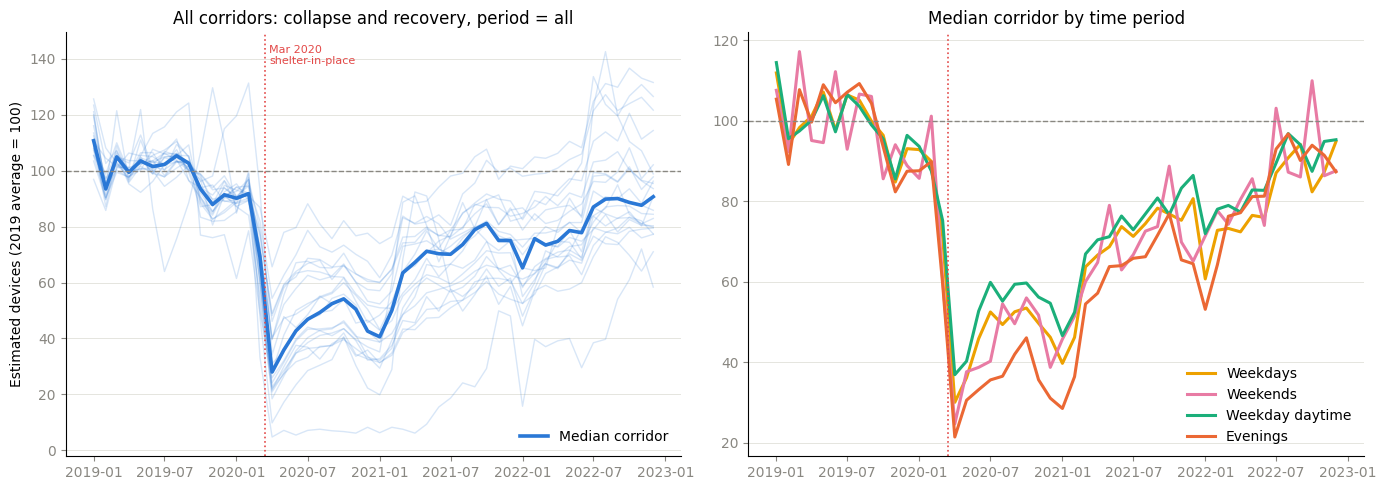

In [6]:
s1_idx = [i for i, m in enumerate(months) if S1_FIRST <= m <= S1_LAST]
s1_months_dt = months_dt.iloc[s1_idx]
base_mask = np.array([m.startswith(BASELINE_YEAR) for m in months])[s1_idx]

index_s1 = {}
for p in TIME_PERIODS:
    f = monthly[p].iloc[s1_idx]
    index_s1[p] = f / f[base_mask].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for slug in slugs:
    ax.plot(s1_months_dt, index_s1["all"][slug], color=CATEGORICAL_PALETTE[0], alpha=0.18, linewidth=1)
ax.plot(s1_months_dt, index_s1["all"].median(axis=1), color=CATEGORICAL_PALETTE[0], linewidth=2.6, label="Median corridor")
ax.axhline(100, color=CHART_MUTED_TEXT, linestyle="--", linewidth=1)
ax.axvline(pd.Timestamp("2020-03-15"), color=CATEGORICAL_PALETTE[7], linestyle=":", linewidth=1.2)
ax.text(pd.Timestamp("2020-03-25"), ax.get_ylim()[1] * 0.97, "Mar 2020\nshelter-in-place", fontsize=8, color=CATEGORICAL_PALETTE[7], va="top")
ax.set_ylabel("Estimated devices (2019 average = 100)")
ax.set_title("All corridors: collapse and recovery, period = all")
ax.legend(frameon=False, loc="lower right")
style_axis(ax)

ax = axes[1]
for p in ["weekdays", "weekends", "nine-five", "evening"]:
    ax.plot(s1_months_dt, index_s1[p].median(axis=1), color=PERIOD_COLORS[p], linewidth=2.2, label=PERIOD_LABELS[p])
ax.axhline(100, color=CHART_MUTED_TEXT, linestyle="--", linewidth=1)
ax.axvline(pd.Timestamp("2020-03-15"), color=CATEGORICAL_PALETTE[7], linestyle=":", linewidth=1.2)
ax.set_title("Median corridor by time period")
ax.legend(frameon=False, loc="lower right")
style_axis(ax)
plt.tight_layout()
plt.show()

/tmp/ipykernel_117875/3738264038.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  same_month_2019 = f[months.index(f"2019{COVID_MONTH[4:]}")]
/tmp/ipykernel_117875/3738264038.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  same_month_2019 = f[months.index(f"2019{COVID_MONTH[4:]}")]
/tmp/ipykernel_117875/3738264038.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  same_month_2019 = f[months.index(f"2019{COVID_MONTH[4:]}")]
/

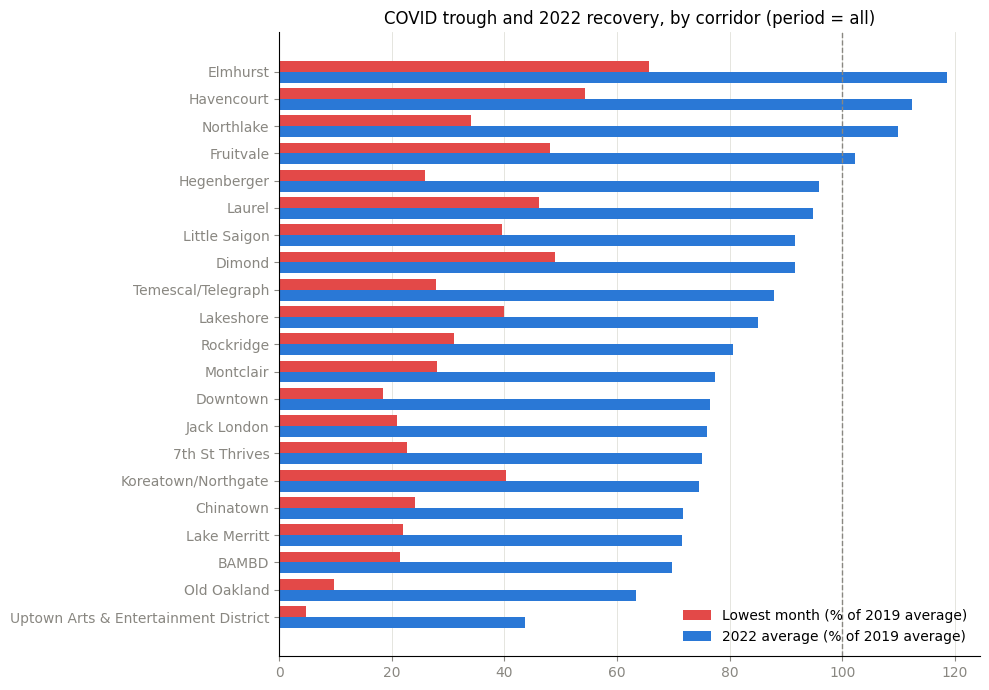

,name,trough_pct_of_2019,trough_month,2022_pct_of_2019
slug,,,,
uptown_arts_and_entertainment_district,Uptown Arts & Entertainment District,5.0,202004,44.0
old_oakland,Old Oakland,10.0,202004,63.0
bambd,BAMBD,22.0,202004,70.0
lake_merritt,Lake Merritt,22.0,202004,72.0
chinatown,Chinatown,24.0,202004,72.0
koreatown_northgate,Koreatown/Northgate,40.0,202004,75.0
7th_st_thrives,7th St Thrives,23.0,202004,75.0
jack_london,Jack London,21.0,202004,76.0
downtown,Downtown,18.0,202004,77.0


In [7]:
# Per-corridor shock and recovery
i_covid = months.index(COVID_MONTH)
rows = []
for slug in slugs:
    f = monthly["all"][slug]
    same_month_2019 = f[months.index(f"2019{COVID_MONTH[4:]}")]
    rows.append({
        "slug": slug, "name": names[slug],
        "covid_low_vs_2019": f[COVID_MONTH] / same_month_2019 * 100,
        "trough_pct_of_2019": index_s1["all"][slug].min(),
        "trough_month": index_s1["all"][slug].idxmin(),
    })
covid = pd.DataFrame(rows).set_index("slug")
yr = pd.Series([m[:4] for m in months])
covid["2022_pct_of_2019"] = [monthly["all"][s][(yr == RECOVERY_YEAR).values].mean() / monthly["all"][s][(yr == BASELINE_YEAR).values].mean() * 100 for s in slugs]
covid = covid.sort_values("2022_pct_of_2019")

fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(covid))
ax.barh(y + 0.2, covid.trough_pct_of_2019, height=0.4, color=CATEGORICAL_PALETTE[7], label="Lowest month (% of 2019 average)")
ax.barh(y - 0.2, covid["2022_pct_of_2019"], height=0.4, color=CATEGORICAL_PALETTE[0], label="2022 average (% of 2019 average)")
ax.set_yticks(y, covid.name)
ax.axvline(100, color=CHART_MUTED_TEXT, linestyle="--", linewidth=1)
ax.legend(frameon=False, loc="lower right")
ax.set_title("COVID trough and 2022 recovery, by corridor (period = all)")
style_axis(ax, "x")
plt.tight_layout()
plt.show()

covid[["name", "trough_pct_of_2019", "trough_month", "2022_pct_of_2019"]].round(0)

In [8]:
# Which periods recovered best? Median across corridors of the 2022 average vs 2019 average
rec = pd.DataFrame({
    p: [monthly[p][s][(yr == RECOVERY_YEAR).values].mean() / monthly[p][s][(yr == BASELINE_YEAR).values].mean() * 100 for s in slugs]
    for p in TIME_PERIODS
}, index=slugs)
print("2022 as % of 2019 (median / min / max across corridors):")
display(pd.DataFrame({"median": rec.median(), "min": rec.min(), "max": rec.max()}).rename(index=PERIOD_LABELS).round(0).T)

2022 as % of 2019 (median / min / max across corridors):


,All,Evenings,Weekday daytime,Weekdays,Weekends
median,81.0,82.0,85.0,79.0,87.0
min,44.0,48.0,38.0,43.0,47.0
max,119.0,124.0,119.0,119.0,125.0


## 3. Who gained and lost share?

A corridor's **share of the 21-corridor total** (monthly devices as a % of the sum over all corridors) cancels the
provider's overall scale, so it can be followed across the break, with the uncertainty band from `04_`: a move of less than
x/1.42 to x*1.42 across the break could be the provider alone. Inside a segment no band is needed.

The heatmap ranks the corridors by their share each year (1 = largest). 2023 is omitted because it mixes S2 (excluded) and S3.

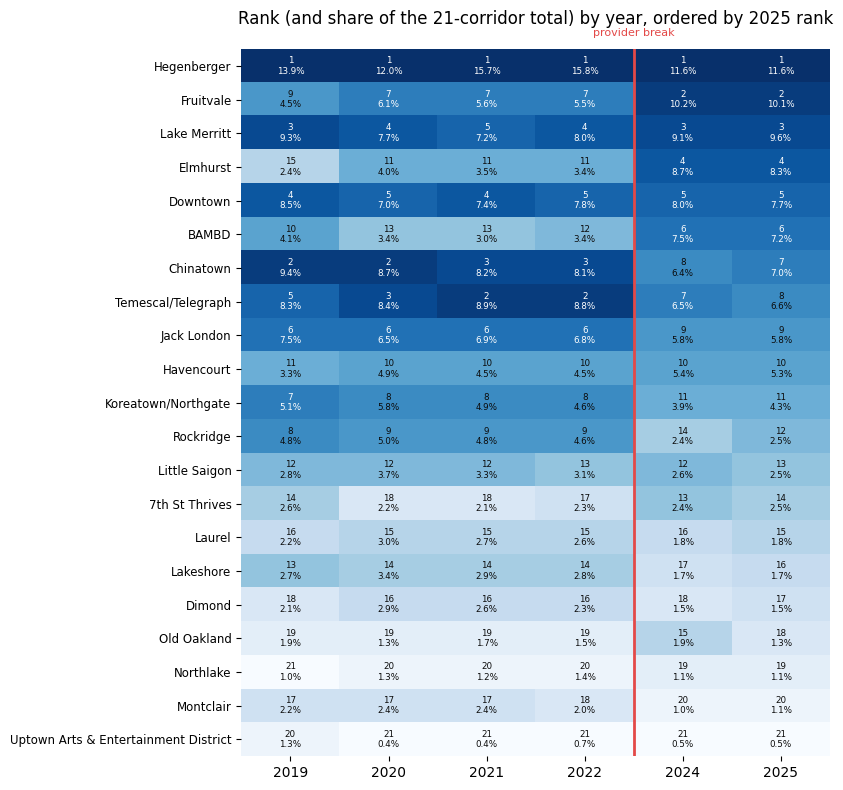

9 of 21 corridors change share across the break by more than the x1.416 band


,share 2019 %,share 2022 %,share 2024 %,share 2025 %,within S1: 2022 vs 2019 (x),within S3: 2025 vs 2024 (x),ACROSS break: 2024 vs 2022 (x),across beyond band?
name,,,,,,,,
Elmhurst,2.39,3.40,8.72,8.26,1.42,0.95,2.56,True
BAMBD,4.06,3.40,7.49,7.19,0.84,0.96,2.20,True
Fruitvale,4.50,5.53,10.15,10.14,1.23,1.00,1.84,True
Old Oakland,1.92,1.46,1.88,1.32,0.76,0.70,1.29,False
Havencourt,3.35,4.51,5.44,5.29,1.35,0.97,1.21,False
Lake Merritt,9.29,7.96,9.08,9.60,0.86,1.06,1.14,False
7th St Thrives,2.59,2.33,2.45,2.46,0.90,1.01,1.05,False
Downtown,8.50,7.81,8.02,7.73,0.92,0.96,1.03,False
Little Saigon,2.75,3.06,2.64,2.50,1.11,0.95,0.87,False


In [9]:
share_m = pd.DataFrame({s: C[s]["share_of_total"]["all"] for s in slugs}, index=months).astype(float)
years = ["2019", "2020", "2021", "2022", "2024", "2025"]
share_y = pd.DataFrame({y: share_m[[m.startswith(y) for m in months]].mean() for y in years})
rank_y = share_y.rank(ascending=False, method="min")

order = rank_y["2025"].sort_values().index
fig, ax = plt.subplots(figsize=(8.5, 8))
im = ax.imshow(rank_y.loc[order].values, cmap="Blues_r", aspect="auto", vmin=1, vmax=21)
ax.set_xticks(range(len(years)), years)
ax.set_yticks(range(len(order)), [names[s] for s in order], fontsize=8.5)
for i, s in enumerate(order):
    for j, y in enumerate(years):
        ax.text(j, i, f"{int(rank_y.loc[s, y])}\n{share_y.loc[s, y]:.1f}%", ha="center", va="center", fontsize=6.3, color="white" if rank_y.loc[s, y] < 8 else "#0b0b0b")
ax.axvline(3.5, color="#e34948", linewidth=2)
ax.text(3.5, -0.9, "provider break", color="#e34948", ha="center", fontsize=8)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_title("Rank (and share of the 21-corridor total) by year, ordered by 2025 rank", pad=18)
plt.tight_layout()
plt.show()

band_f = meta["comparability"]["share_band_factor"]
mv = pd.DataFrame({
    "name": [names[s] for s in slugs],
    "share 2019 %": share_y["2019"], "share 2022 %": share_y["2022"], "share 2024 %": share_y["2024"], "share 2025 %": share_y["2025"],
}, index=slugs)
mv["within S1: 2022 vs 2019 (x)"] = mv["share 2022 %"] / mv["share 2019 %"]
mv["within S3: 2025 vs 2024 (x)"] = mv["share 2025 %"] / mv["share 2024 %"]
mv["ACROSS break: 2024 vs 2022 (x)"] = mv["share 2024 %"] / mv["share 2022 %"]
mv["across beyond band?"] = (mv["ACROSS break: 2024 vs 2022 (x)"] > band_f) | (mv["ACROSS break: 2024 vs 2022 (x)"] < 1 / band_f)
print(f"{int(mv['across beyond band?'].sum())} of {len(mv)} corridors change share across the break by more than the x{band_f} band")
mv.set_index("name").round(2).sort_values("ACROSS break: 2024 vs 2022 (x)", ascending=False)

## 4. Seasonality

Seasonal shape is only meaningful *within a year* that sits wholly inside one segment, so three calendar years
are compared: **2019** (pre-COVID, S1), **2024** and **2025** (both S3). Each month is indexed to that year's
own monthly average (100).

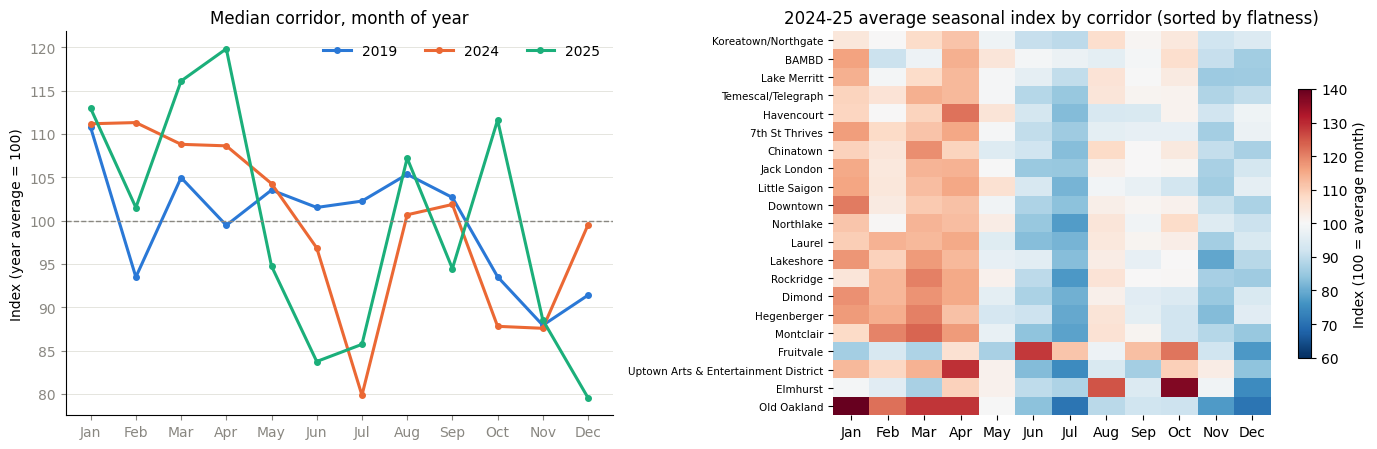

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax = axes[0]
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
season = {}
for color, year in zip(CATEGORICAL_PALETTE, SEASON_YEARS):
    mask = (yr == year).values
    f = monthly["all"].loc[mask]
    idx = f / f.mean() * 100
    season[year] = idx.set_index(pd.Index(range(12)))
    ax.plot(range(12), idx.median(axis=1).values, color=color, linewidth=2.2, marker="o", markersize=4, label=year)
ax.axhline(100, color=CHART_MUTED_TEXT, linestyle="--", linewidth=1)
ax.set_xticks(range(12), month_names)
ax.set_ylabel("Index (year average = 100)")
ax.set_title("Median corridor, month of year")
ax.legend(frameon=False, ncol=3)
style_axis(ax)

ax = axes[1]
mat = pd.concat([season["2024"], season["2025"]]).groupby(level=0).mean().T
mat.index = [names[s] for s in mat.index]
mat = mat.loc[mat.std(axis=1).sort_values().index]
im = ax.imshow(mat.values, cmap="RdBu_r", vmin=60, vmax=140, aspect="auto")
ax.set_xticks(range(12), month_names)
ax.set_yticks(range(len(mat)), mat.index, fontsize=7.5)
ax.set_title("2024-25 average seasonal index by corridor (sorted by flatness)")
for s in ax.spines.values():
    s.set_visible(False)
plt.colorbar(im, ax=ax, shrink=0.7, label="Index (100 = average month)")
plt.tight_layout()
plt.show()

## 5. Origin over time, inside each segment

Origin *shares* are less sensitive to panel size than levels, but they are **not immune to the provider change**: the Oakland
share steps up at the S2/S3 boundary in most corridors, the signature of a different panel (geographic mix and home matching).
So trends are read **inside** each segment: the left panel plots each segment on its own, with the break left open, and the right
panel shows each corridor's *gap to the median corridor* in the same half-year, which removes any panel-wide shift.

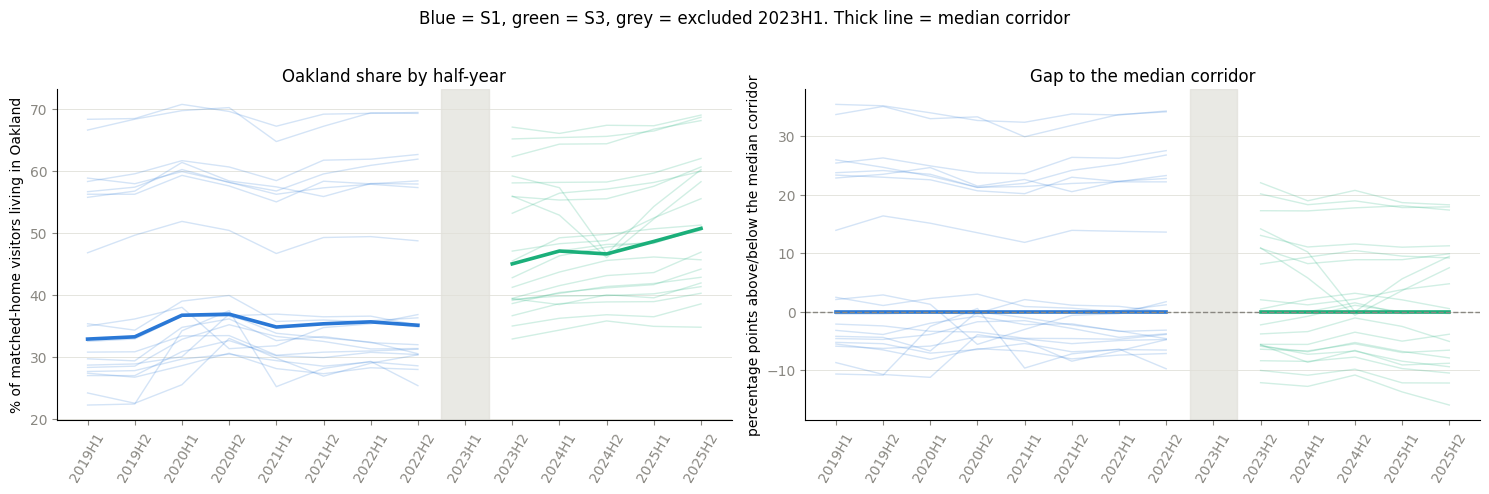

Median Oakland share by year (across corridors); the 2022 -> 2024 step is the provider change, not a real shift:


year,2019,2020,2021,2022,2024,2025
median % from Oakland,33.1,36.6,35.1,35.8,47.6,49.6


Change in Oakland share WITHIN one segment:


,S1: 2022 minus 2019 (pts),S3: 2025 minus 2024 (pts)
min,-0.8,-0.1
median,1.9,2.0
max,6.4,6.0


In [11]:
oc = origin_cat[origin_cat.home_geography.isin(["Oakland", "San Francisco", "Rest East Bay", "Rest Bay Area"])].copy()
oc["half_year"] = oc.year_month.astype(str).str[:4] + "H" + np.where(oc.year_month.astype(str).str[4:].astype(int) <= 6, "1", "2")
oc = oc[~oc.year_month.astype(str).between("202301", "202306")]                    # excluded S2
hy = oc[oc.time_period == "all"].groupby(["corridor_slug", "half_year", "home_geography"]).normalized_unique_devices.sum().unstack("home_geography")
hy_pct = hy.div(hy.sum(axis=1), axis=0) * 100

half_years = meta["half_years"]
oak_hy = hy_pct["Oakland"].unstack("corridor_slug").reindex(half_years)         # 2023H1 is NaN
s1_hys = [h for h in half_years if h <= "2022H2"]
s3_hys = [h for h in half_years if h >= "2023H2"]
gap_hy = oak_hy.sub(oak_hy.median(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharex=True)
for ax, frame, title, ylab in [
    (axes[0], oak_hy, "Oakland share by half-year", "% of matched-home visitors living in Oakland"),
    (axes[1], gap_hy, "Gap to the median corridor", "percentage points above/below the median corridor"),
]:
    for hys, color in [(s1_hys, SEG_COLOR["S1"]), (s3_hys, SEG_COLOR["S3"])]:
        x = [half_years.index(h) for h in hys]
        for slug in slugs:
            ax.plot(x, frame.loc[hys, slug], color=color, alpha=0.2, linewidth=1)
        ax.plot(x, frame.loc[hys].median(axis=1), color=color, linewidth=2.6)
    ax.axvspan(7.5, 8.5, color=CHART_GRID_COLOR, alpha=0.7, zorder=0)
    ax.set_xticks(range(len(half_years)), half_years, rotation=60)
    ax.set_title(title)
    ax.set_ylabel(ylab)
    style_axis(ax)
axes[1].axhline(0, color=CHART_MUTED_TEXT, linestyle="--", linewidth=1)
plt.suptitle("Blue = S1, green = S3, grey = excluded 2023H1. Thick line = median corridor", y=1.02)
plt.tight_layout()
plt.show()

oak_year = oc[oc.time_period == "all"].assign(year=lambda d: d.year_month.astype(str).str[:4]).groupby(["corridor_slug", "year", "home_geography"]).normalized_unique_devices.sum().unstack("home_geography")
oak_year = (oak_year["Oakland"] / oak_year.sum(axis=1) * 100).unstack("year")
within = pd.DataFrame({
    "S1: 2022 minus 2019 (pts)": oak_year["2022"] - oak_year["2019"],
    "S3: 2025 minus 2024 (pts)": oak_year["2025"] - oak_year["2024"],
})
print("Median Oakland share by year (across corridors); the 2022 -> 2024 step is the provider change, not a real shift:")
display(oak_year[["2019", "2020", "2021", "2022", "2024", "2025"]].median().round(1).to_frame("median % from Oakland").T)
print("Change in Oakland share WITHIN one segment:")
display(within.describe().loc[["min", "50%", "max"]].round(1).rename(index={"50%": "median"}))

## 6. Catchment maps: all 21 corridors

The same choropleth the web map draws for each corridor (period = all, quintile breaks from `legend_breaks.json`),
with the corridor outlined in black. Use it to eyeball which corridors have tight local catchments and which
spread across the whole city.

/tmp/ipykernel_117875/2213908424.py:27: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  polys[polys.corridor_slug == slug].plot(ax=ax, facecolor="none", edgecolor="#0b0b0b", linewidth=1.3)


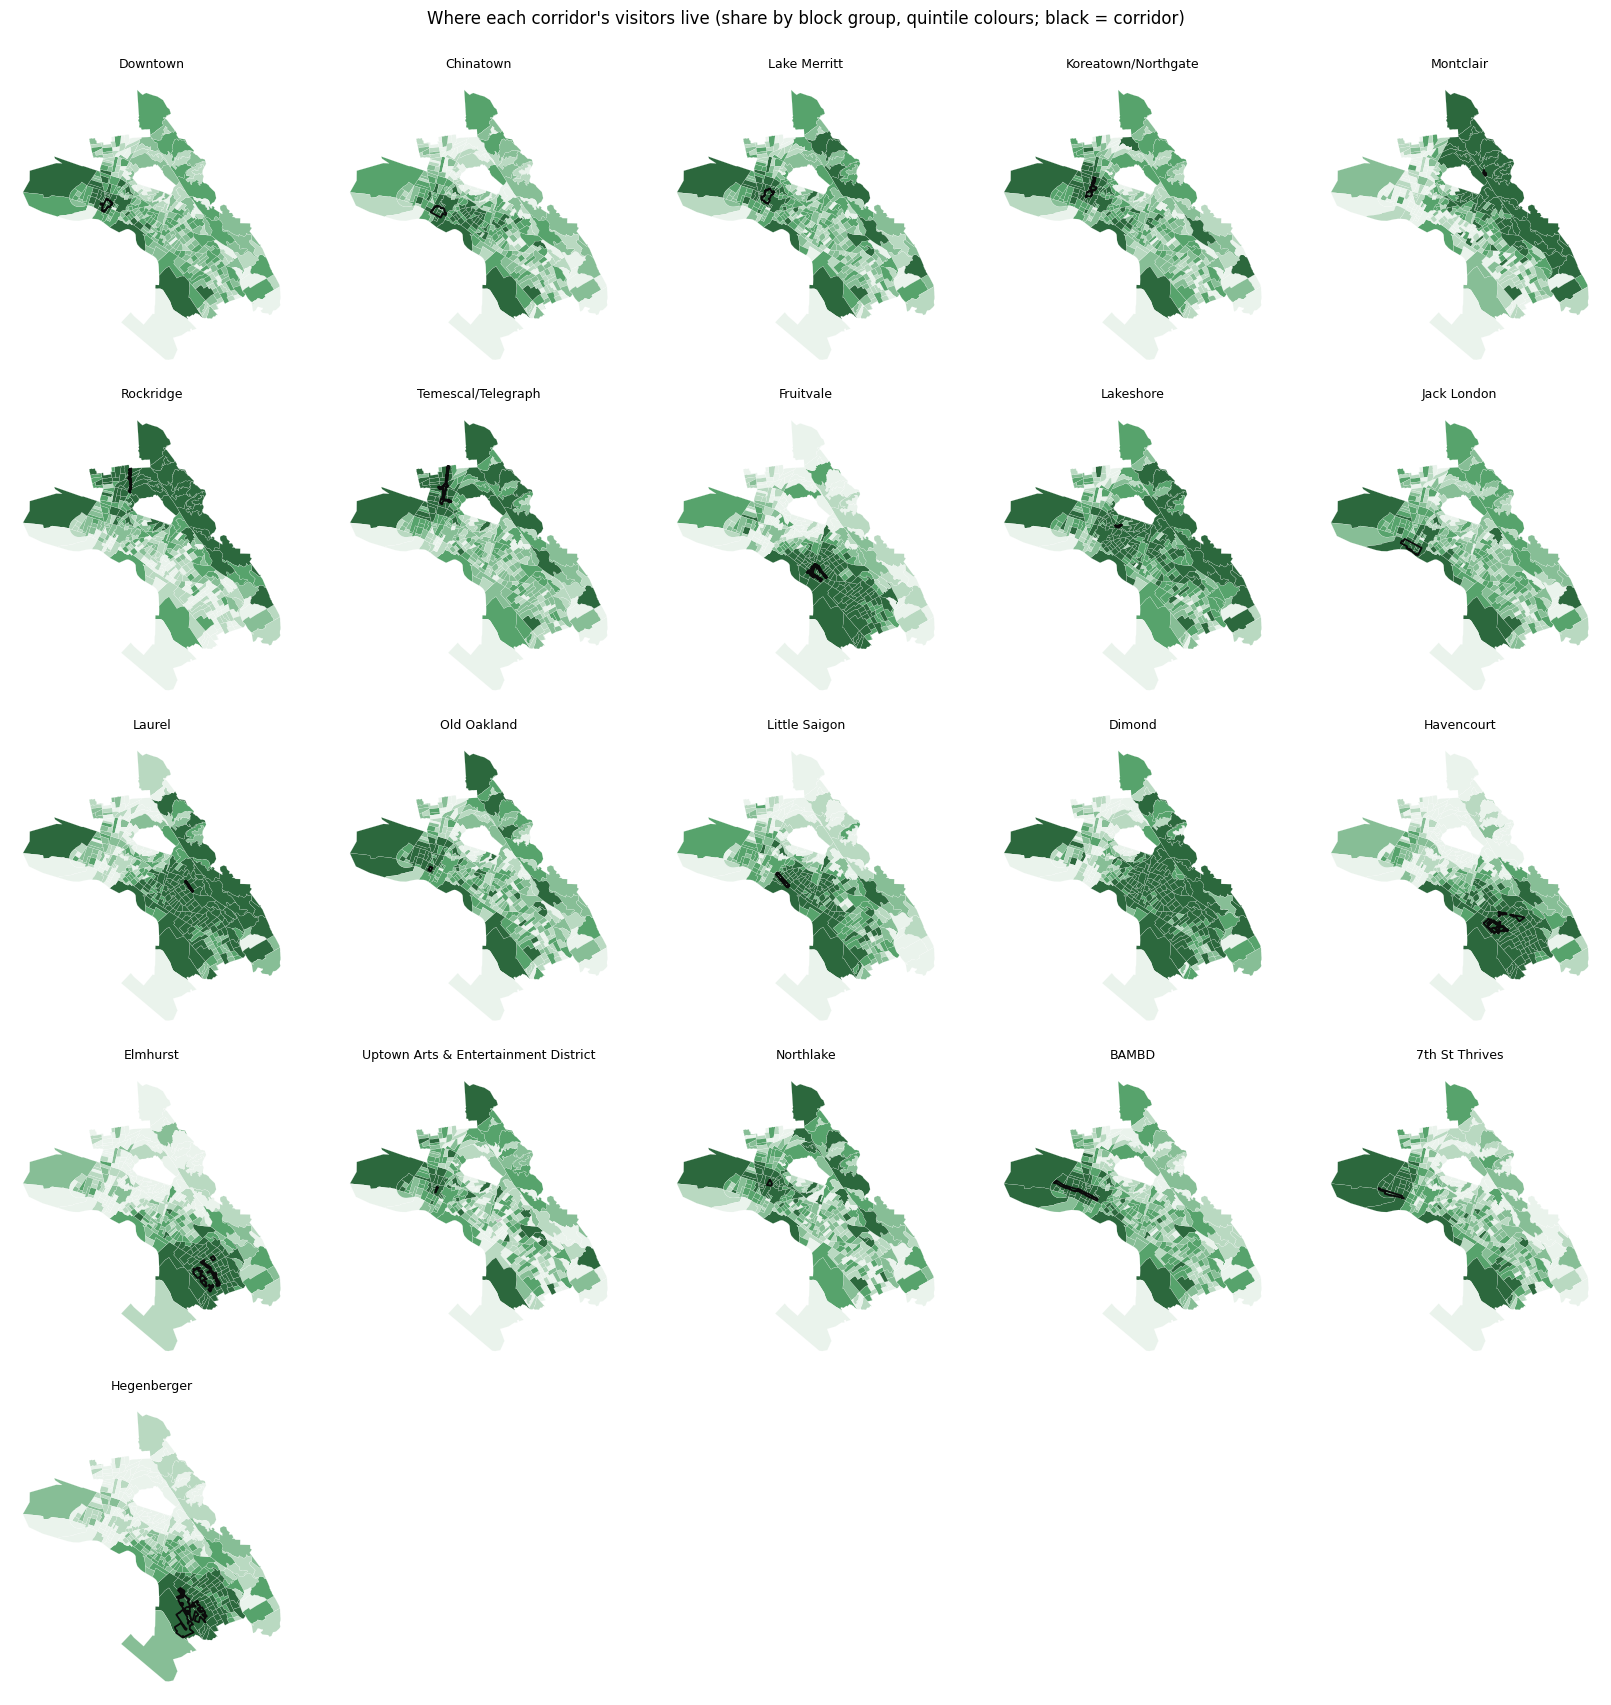

In [12]:
oak_bg = gpd.read_file(OAK_BG_GEOJSON).to_crs(WORK_CRS)
lookup = pd.read_csv(CORRIDOR_LOOKUP_CSV)

map_corr = gpd.read_file(MAP_CORRIDORS_GEOJSON).to_crs(WORK_CRS)
map_corr["name"] = map_corr.corridor_name.str.replace("\xa0", " ").str.strip()
set2_poly = gpd.read_file(SET2_CORRIDORS_GPKG).to_crs(WORK_CRS)
set2_poly["name"] = set2_poly.corridor_name
polys = pd.concat([map_corr[map_corr.name.isin(lookup[lookup.corridor_set == 1].corridor_name)][["name", "geometry"]], set2_poly[["name", "geometry"]]])
polys = polys.merge(lookup[["corridor_slug", "corridor_name"]], left_on="name", right_on="corridor_name")
polys = gpd.GeoDataFrame(polys, geometry="geometry", crs=WORK_CRS)

breaks_all = legend_breaks["pooled"]["all"]
share = bg_origin[bg_origin.time_period == "all"].pivot(index="bg_geoid", columns="corridor_slug", values="pct_share")


def shade(v):
    if pd.isna(v) or v <= 0:
        return "#cbcbcb"
    return GREEN_RAMP[int(np.searchsorted(breaks_all, v, side="right"))]


n_rows = int(np.ceil(len(slugs) / N_MAP_COLS))
fig, axes = plt.subplots(n_rows, N_MAP_COLS, figsize=(3.3 * N_MAP_COLS, 3.4 * n_rows))
for ax, slug in zip(axes.flat, slugs):
    colors = oak_bg.GEOID.map(lambda g: shade(share.loc[g, slug]) if g in share.index else "#cbcbcb")
    oak_bg.plot(ax=ax, color=colors, edgecolor="white", linewidth=0.1)
    polys[polys.corridor_slug == slug].plot(ax=ax, facecolor="none", edgecolor="#0b0b0b", linewidth=1.3)
    ax.set_title(names[slug], fontsize=9)
    ax.set_axis_off(); ax.set_aspect("equal")
for ax in list(axes.flat)[len(slugs):]:
    ax.set_visible(False)
plt.suptitle("Where each corridor's visitors live (share by block group, quintile colours; black = corridor)", y=1.0)
plt.tight_layout()
plt.show()

## 7. Catchment overlap

Two corridors **share a catchment** if the same block groups send them a similar mix of visitors. Measured as the
**cosine similarity** between corridors' block-group share vectors (1 = identical geographic profile,
0 = no overlap). High similarity points to corridors that compete for, or complement, the same neighbourhoods.

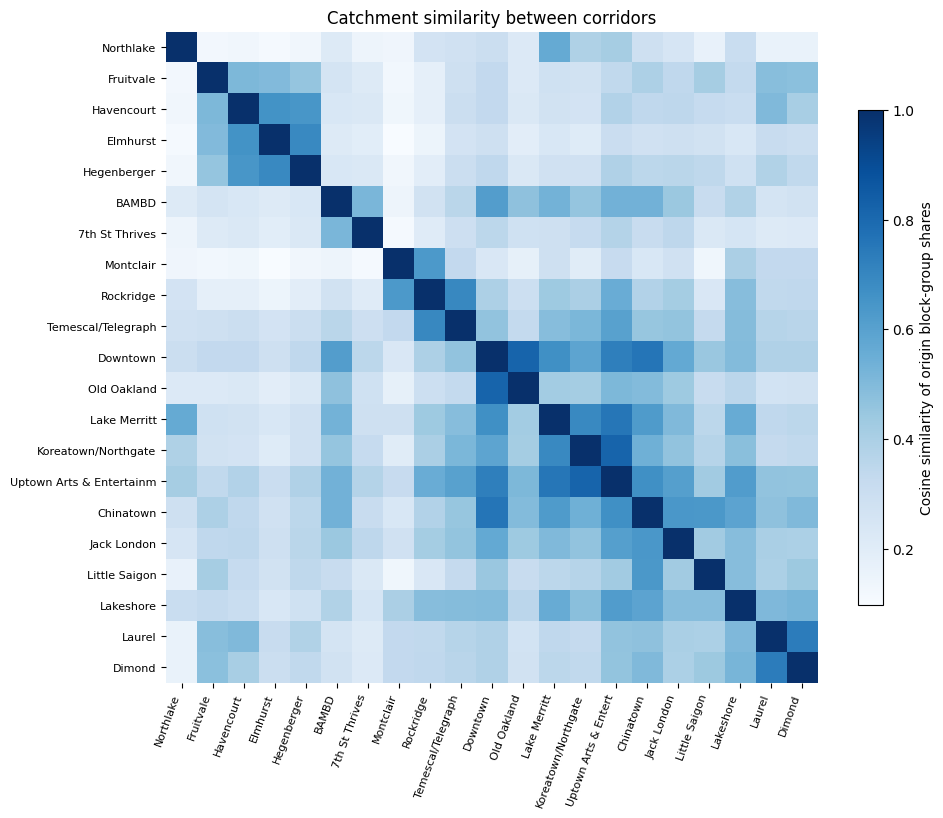

Most similar catchments:


,corridor_a,corridor_b,similarity
69,Koreatown/Northgate,Uptown Arts & Entertainment District,0.820
10,Downtown,Old Oakland,0.819
0,Downtown,Chinatown,0.759
52,Lake Merritt,Uptown Arts & Entertainment District,0.754
157,Laurel,Dimond,0.733
15,Downtown,Uptown Arts & Entertainment District,0.723
90,Rockridge,Temescal/Telegraph,0.697
199,Elmhurst,Hegenberger,0.692


Most distinctive catchments (lowest average similarity to all others):


,Northlake,Montclair,7th St Thrives,Elmhurst,Fruitvale,Hegenberger
distinctiveness,0.764,0.762,0.734,0.711,0.674,0.672


In [13]:
X = share.reindex(columns=slugs).fillna(0).T                 # corridor x block group
norm = np.linalg.norm(X.values, axis=1, keepdims=True)
sim = pd.DataFrame((X.values / norm) @ (X.values / norm).T, index=slugs, columns=slugs)

Zl = linkage(X.values / norm, method="average", metric="cosine")
order = [slugs[i] for i in leaves_list(Zl)]

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(sim.loc[order, order].values, cmap="Blues", vmin=sim.values[np.triu_indices(len(slugs), 1)].min(), vmax=1)
ax.set_xticks(range(len(order)), [names[s][:20] for s in order], rotation=70, ha="right", fontsize=8)
ax.set_yticks(range(len(order)), [names[s][:24] for s in order], fontsize=8)
for s in ax.spines.values():
    s.set_visible(False)
plt.colorbar(im, ax=ax, shrink=0.7, label="Cosine similarity of origin block-group shares")
ax.set_title("Catchment similarity between corridors")
plt.tight_layout()
plt.show()

pairs = sim.where(np.triu(np.ones(sim.shape), 1).astype(bool)).stack().rename("similarity").reset_index()
pairs.columns = ["corridor_a", "corridor_b", "similarity"]
pairs[["corridor_a", "corridor_b"]] = pairs[["corridor_a", "corridor_b"]].map(names.get)
print("Most similar catchments:")
display(pairs.sort_values("similarity", ascending=False).head(8).round(3))
print("Most distinctive catchments (lowest average similarity to all others):")
distinct = (1 - (sim.sum() - 1) / (len(slugs) - 1)).rename("distinctiveness").sort_values(ascending=False)
distinct.index = [names[s] for s in distinct.index]
display(distinct.head(6).round(3).to_frame().T)

## 8. Who lives where visitors come from?

Weighting each Oakland block group's demographics by its share of a corridor's visitors gives the *average
neighbourhood profile of the visitors who live in Oakland*, compared with the Oakland-wide, population-weighted
baseline. This is an **ecological** inference: it describes the neighbourhoods visitors come from, not the visitors
themselves (and ignores the share who live outside Oakland).

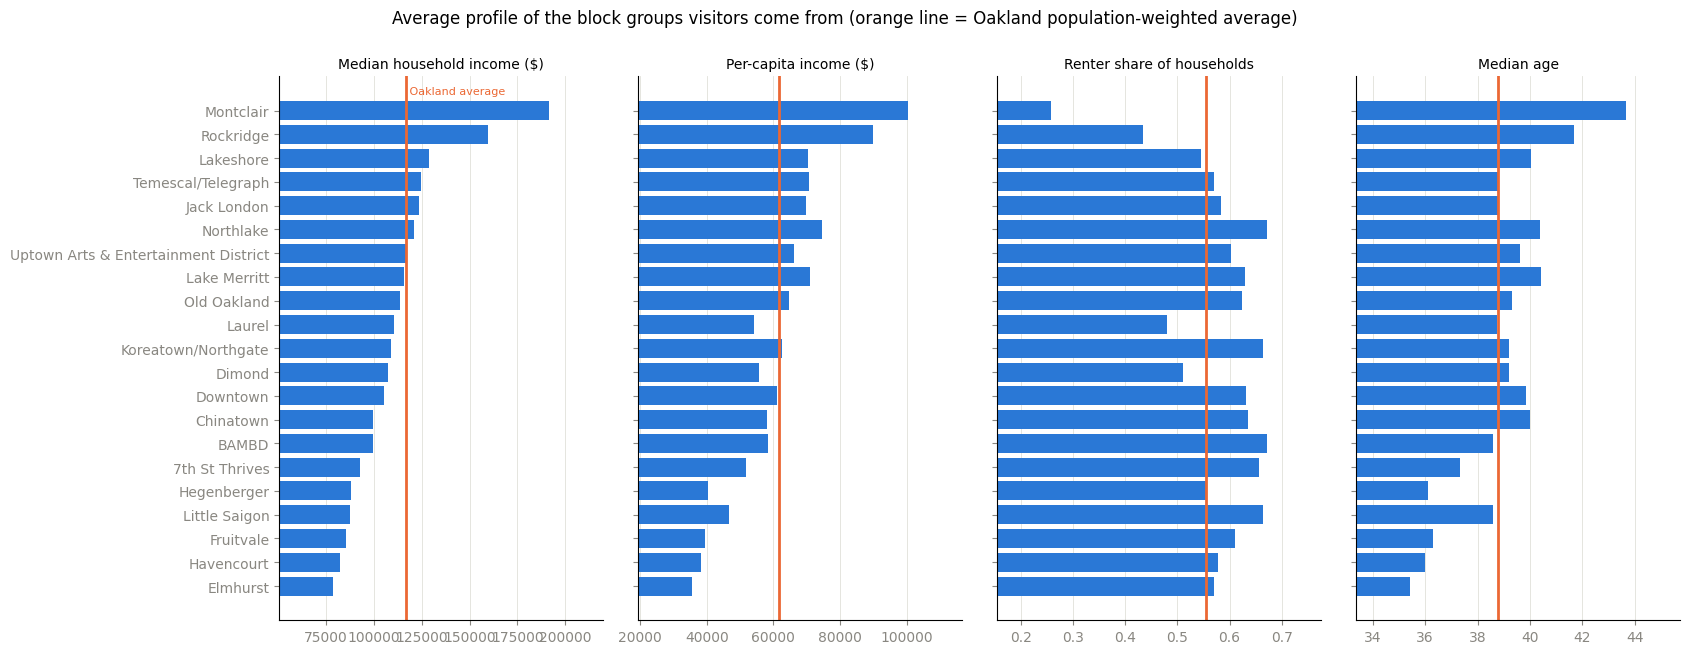

,median_household_income,per_capita_income,renter_share,median_age
name,,,,
Montclair,191493.86,100431.84,0.26,43.67
Rockridge,159839.77,90024.36,0.43,41.70
Lakeshore,128654.99,70446.84,0.54,40.03
Temescal/Telegraph,124660.33,70768.54,0.57,38.83
Jack London,123502.52,69745.18,0.58,38.82
Northlake,120799.15,74508.47,0.67,40.40
Oakland average,116787.20,61756.67,0.56,38.77
Uptown Arts & Entertainment District,116699.01,66116.70,0.60,39.62
Lake Merritt,115796.08,70908.88,0.63,40.41


In [14]:
demo = gpd.read_file(OAK_BG_GEOJSON).set_index("GEOID")
for col in DEMOGRAPHIC_VARS:
    demo[col] = pd.to_numeric(demo[col], errors="coerce")
demo["pop_count"] = pd.to_numeric(demo.pop_count, errors="coerce").fillna(0)

def weighted_mean(values, weights):
    ok = values.notna() & weights.notna() & (weights > 0)
    return float((values[ok] * weights[ok]).sum() / weights[ok].sum()) if ok.any() else np.nan

baseline = {col: weighted_mean(demo[col], demo.pop_count) for col in DEMOGRAPHIC_VARS}

rows = []
for slug in slugs:
    w = share[slug].reindex(demo.index).fillna(0)
    rows.append({"slug": slug, "name": names[slug], **{col: weighted_mean(demo[col], w) for col in DEMOGRAPHIC_VARS}})
vis = pd.DataFrame(rows).set_index("slug")

fig, axes = plt.subplots(1, 4, figsize=(17, 6.5), sharey=True)
order_inc = vis.sort_values("median_household_income").name
for ax, (col, label) in zip(axes, DEMOGRAPHIC_VARS.items()):
    v = vis.set_index("name").loc[order_inc, col]
    ax.barh(v.index, v.values, color=CATEGORICAL_PALETTE[0])
    ax.axvline(baseline[col], color=CATEGORICAL_PALETTE[1], linewidth=2)
    lo, hi = min(v.min(), baseline[col]), max(v.max(), baseline[col])
    pad = (hi - lo) * 0.25
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_title(label, fontsize=10)
    style_axis(ax, "x")
axes[0].text(baseline["median_household_income"], len(vis) - 0.4, " Oakland average", color=CATEGORICAL_PALETTE[1], fontsize=8, va="bottom")
plt.suptitle("Average profile of the block groups visitors come from (orange line = Oakland population-weighted average)", y=1.0)
plt.tight_layout()
plt.show()

vis_view = vis.set_index("name")[list(DEMOGRAPHIC_VARS)].round(2)
vis_view.loc["Oakland average"] = pd.Series(baseline).round(2)
vis_view.sort_values("median_household_income", ascending=False)

## 9. Which council districts over-index at which corridors?

For each corridor, compare the share of its **Oakland-origin** visitors that live in each district with that
district's share of Oakland's population. An index of 2.0 means a district sends twice as many visitors to the
corridor as its population share would suggest; 0.5 means half as many. This removes the effect of districts
being different sizes and highlights genuine affinities.

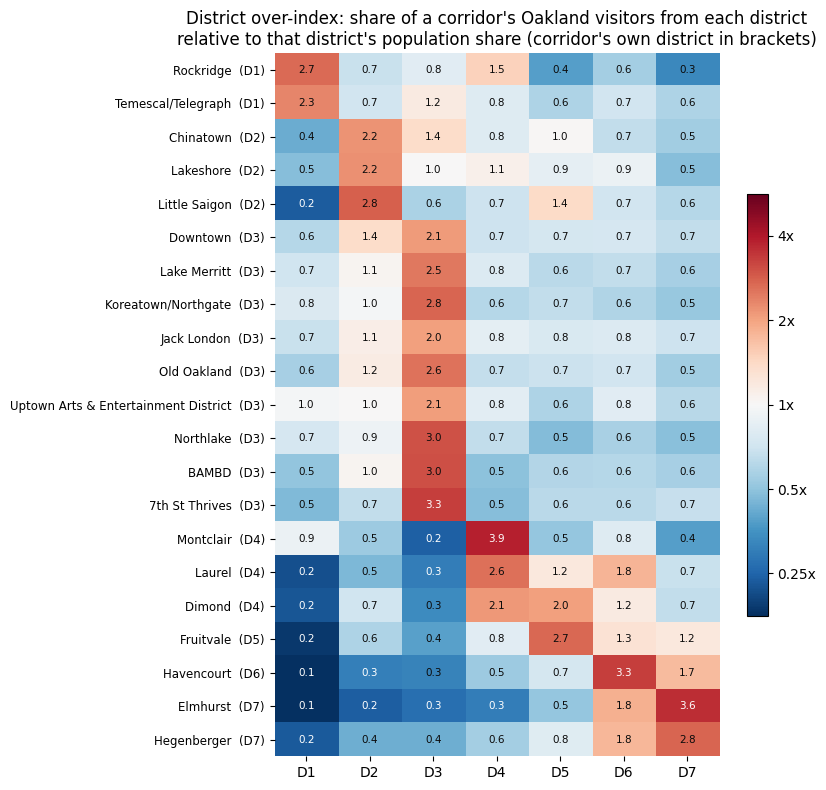

How strongly does each corridor over-index in its own district?


,Montclair,Elmhurst,7th St Thrives,Havencourt,BAMBD,Northlake,Little Saigon,Koreatown/Northgate,Hegenberger,Fruitvale,...,Laurel,Old Oakland,Lake Merritt,Temescal/Telegraph,Lakeshore,Chinatown,Dimond,Downtown,Uptown Arts & Entertainment District,Jack London
own_district_index,3.85,3.62,3.32,3.31,3.04,3.01,2.83,2.75,2.75,2.72,...,2.58,2.56,2.5,2.32,2.22,2.17,2.13,2.1,2.07,2.03


In [15]:
dist = pd.read_csv(DISTRICT_ORIGIN_CSV)
bgd = pd.read_csv(BG_DISTRICT_CSV, dtype={"bg_geoid": str})
pop = demo.pop_count
dist_pop = (bgd.assign(p=bgd.bg_geoid.map(pop) * bgd.weight).groupby("district").p.sum())
dist_pop_share = dist_pop / dist_pop.sum()

d_all = dist[dist.time_period == "all"].pivot(index="corridor_slug", columns="district", values="pct").loc[slugs]
d_share = d_all.div(d_all.sum(axis=1), axis=0)
over_index = d_share.div(dist_pop_share, axis=1)

primary = pd.Series({s: C[s]["primary_district"] for s in slugs})
order = primary.sort_values(kind="stable").index
mat = over_index.loc[order]

fig, ax = plt.subplots(figsize=(8.5, 8))
im = ax.imshow(np.log2(mat.values), cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
ax.set_xticks(range(7), [f"D{d}" for d in mat.columns])
ax.set_yticks(range(len(mat)), [f"{names[s]}  (D{primary[s]})" for s in mat.index], fontsize=8.5)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, f"{mat.values[i, j]:.1f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(np.log2(mat.values[i, j])) > 1.7 else "#0b0b0b")
for s in ax.spines.values():
    s.set_visible(False)
cb = plt.colorbar(im, ax=ax, shrink=0.6)
cb.set_ticks([-2, -1, 0, 1, 2]); cb.set_ticklabels(["0.25x", "0.5x", "1x", "2x", "4x"])
ax.set_title("District over-index: share of a corridor's Oakland visitors from each district\nrelative to that district's population share (corridor's own district in brackets)")
plt.tight_layout()
plt.show()

own = pd.Series({s: over_index.loc[s, primary[s]] for s in slugs}).rename("own_district_index")
own.index = [names[s] for s in own.index]
print("How strongly does each corridor over-index in its own district?")
display(own.sort_values(ascending=False).round(2).to_frame().T)

## Observations

**What can be compared (section 1).** The provider effect is not a common multiplier, so absolute levels are never joined
across the break. A corridor's *share of the 21-corridor total*, its Oakland share and its near/far shares keep their corridor
ranking across the break (rank correlation 0.93-0.94); weekend share, evening share, repeat % and own-district share do not.

**COVID (section 2).** In April 2020 the median corridor was at about **28% of its April 2019 level** (range 5% to 65%).
The downtown, office and nightlife corridors collapsed hardest: Uptown (5%), Old Oakland (10%), Downtown (19%), Jack London
(20%), Lake Merritt and BAMBD (22%). Neighbourhood corridors in East Oakland were the most resilient: Elmhurst (65%),
Havencourt (56%), Dimond (50%). By 2022 the median corridor was back to **81% of its 2019 average**, but the pattern had
split: the downtown group sat at roughly 63-77% (Old Oakland 63%, BAMBD 70%, Chinatown and Lake Merritt 72%, Downtown 77%) while
**Elmhurst (119%), Havencourt (112%), Northlake (110%) and Fruitvale (102%) were above 2019**. Evenings fell furthest in 2020 (trough around
22% of 2019) but by 2022 all five periods had recovered to a similar 79-87%, weekends and weekday daytime best.

**Who gained and lost share (section 3).** Inside S1 the shift is clear and independent of the provider change: between 2019 and 2022
the **East Oakland neighbourhood corridors gained share of the 21-corridor total** (Elmhurst x1.42, Havencourt x1.35, Northlake x1.31,
Fruitvale x1.23) while the **downtown and nightlife corridors lost it** (Uptown x0.51, Old Oakland x0.76, BAMBD x0.84, Chinatown
and Lake Merritt x0.86). Inside S3 the picture is steady: between 2024 and 2025 almost every corridor's share is within about
+/-6% (the exception is Old Oakland, x0.70, a small corridor). Across the break the same direction continues strongly, with
Elmhurst (x2.6), BAMBD (x2.2) and Fruitvale (x1.8) gaining and Montclair, Rockridge, Lakeshore and Dimond falling to about
half or two-thirds of their earlier share; 9 of 21 corridors move by more than the x1.42 provider band. The S1 trend makes a
real shift plausible, but a provider that covers East Oakland better would produce the same picture, so the across-break
part of the movement is flagged rather than asserted.

**Seasonality (section 4).** 2019 is fairly flat (the median corridor stays within about 88-111 of its year average). The S3
years swing more (80-120), partly because the S3 panel itself is growing through the year, so these are less reliable. Both S3
years agree on a summer trough (June-July) and a weaker November-December; individual corridors are idiosyncratic (Old Oakland is
strongest January-April; Fruitvale and Elmhurst spike in single months).

**Origin over time (section 5).** Inside each segment the Oakland share of visitors rises by about **2 percentage points**
(median 33.1% in 2019 to 35.8% in 2022 in S1; 47.6% in 2024 to 49.6% in 2025 in S3), so corridors are drawing slightly more locally
over time. The step from 35.8% (2022) to 47.6% (2024), about 12 points, is the provider change, not a real shift, so absolute
share levels are never compared across it.

**Catchments (sections 6-7).** The maps show the expected decay with distance, and the overlap matrix confirms that geography
is working as it should: the most similar catchments are mostly neighbouring corridors (Koreatown/Northgate and Uptown 0.82,
Downtown and Old Oakland 0.82, Downtown and Chinatown 0.76, Laurel and Dimond 0.73, Rockridge and Temescal 0.70, Elmhurst and
Hegenberger 0.69). The most distinctive catchments belong to Northlake, Montclair, 7th St Thrives, Elmhurst, Fruitvale and Hegenberger.

**Who lives where visitors come from (section 8).** Montclair's Oakland visitors come from the highest-income block groups (average median
household income about $191k vs. about $117k for Oakland as a whole), followed by Rockridge ($160k). The lowest are Elmhurst ($79k),
Havencourt ($82k), Fruitvale ($85k), Little Saigon and Hegenberger ($88k). These describe neighbourhoods visitors come from, not the
visitors themselves.

**Districts (section 9).** Every corridor over-indexes in its own council district, by about 2.0x (Jack London, Uptown) to 3.9x
(Montclair), with Elmhurst, Havencourt and 7th St Thrives around 3.3-3.6x. Beyond that the affinities carve Oakland into broad
zones: Rockridge and Temescal pull from District 1 (2.7x and 2.3x); the downtown group draws heavily on District 3 (2.0-3.3x) and Downtown
and Chinatown also over-index District 2; Laurel and Dimond draw from Districts 4-6; and Hegenberger and Elmhurst draw from
Districts 6-7 (2.8x and 3.6x for District 7). The East Oakland corridors (Havencourt, Elmhurst, Hegenberger) draw almost nobody
from District 1 (index 0.1-0.2), and North Oakland corridors draw little from the east, which suggests a persistent north-south
split in how residents use corridors.